# 1. Air Quality Index (AQI) Analysis and Prediction
**Air Quality Index (AQI) Analysis and Prediction | Python, Pandas, NumPy, Matplotlib, Seaborn, Machine Learning**

• Performed exploratory data analysis to analyze air pollution levels, city-wise and state-wise AQI trends, and identify major pollution patterns.

• Applied data visualization and machine learning techniques to identify pollution hotspots, analyze air quality factors, and predict AQI levels for better environmental insights.

## Phase-1
### Import libraries

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor

### Load and Explore CSV Data file of AQI

In [47]:
air_quality_index=pd.read_csv('aqi_calculated_dataset.csv')

In [48]:
air_quality_index.head()

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg,aqi_sub_index,calculated_aqi,aqi_category,dominant_pollutant,pollutants_with_valid_data,official_aqi_data_criteria_met
0,India,Bihar,Saharsa,"Police Line, Saharsa - BSPCB",23-10-2026 16:00:00,25.892357,86.590325,NH3,4.0,4.0,4.0,1.0,405.4,Severe,CO,7,True
1,India,Bihar,Saharsa,"Police Line, Saharsa - BSPCB",23-10-2026 16:00:00,25.892357,86.590325,OZONE,10.0,19.0,13.0,13.0,405.4,Severe,CO,7,True
2,India,Bihar,Samastipur,"DM Office_Kasipur, Samastipur - BSPCB",23-10-2026 16:00:00,25.859655,85.779440,NH3,1.0,1.0,1.0,0.2,84.8,Satisfactory,PM2.5,6,True
3,India,Bihar,Samastipur,"DM Office_Kasipur, Samastipur - BSPCB",23-10-2026 16:00:00,25.859655,85.779440,OZONE,6.0,6.0,6.0,6.0,84.8,Satisfactory,PM2.5,6,True
4,India,Bihar,Sasaram,"Dada Peer, Sasaram - BSPCB",23-10-2026 16:00:00,24.952822,84.002396,CO,9.0,14.0,12.0,228.3,228.3,Poor,CO,5,True


In [49]:
air_quality_index.tail()

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg,aqi_sub_index,calculated_aqi,aqi_category,dominant_pollutant,pollutants_with_valid_data,official_aqi_data_criteria_met
3684,India,West Bengal,Kolkata,"Rabindra Bharati University, Kolkata - WBPCB",23-10-2026 16:00:00,22.627847,88.380669,SO2,4.0,8.0,6.0,7.5,403.9,Severe,CO,7,True
3685,India,West Bengal,Kolkata,"Rabindra Sarobar, Kolkata - WBPCB",23-10-2026 16:00:00,22.511060,88.351420,PM10,55.0,70.0,61.0,61.0,403.9,Severe,CO,7,True
3686,India,West Bengal,Kolkata,"Ballygunge, Kolkata - WBPCB",23-10-2026 16:00:00,22.536751,88.363802,PM10,58.0,85.0,74.0,74.0,376.6,Very Poor,CO,7,True
3687,India,West Bengal,Kolkata,"Ballygunge, Kolkata - WBPCB",23-10-2026 16:00:00,22.536751,88.363802,CO,28.0,32.0,30.0,376.6,376.6,Very Poor,CO,7,True
3688,India,West Bengal,Siliguri,"Ward-32 Bapupara, Siliguri - WBPCB",23-10-2026 16:00:00,26.687923,88.415250,CO,12.0,34.0,25.0,347.3,347.3,Very Poor,CO,7,True


In [50]:
## Checking data types of all columns
air_quality_index.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3689 entries, 0 to 3688
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   country                         3689 non-null   object 
 1   state                           3689 non-null   object 
 2   city                            3689 non-null   object 
 3   station                         3689 non-null   object 
 4   last_update                     3689 non-null   object 
 5   latitude                        3689 non-null   float64
 6   longitude                       3689 non-null   float64
 7   pollutant_id                    3689 non-null   object 
 8   pollutant_min                   3364 non-null   float64
 9   pollutant_max                   3364 non-null   float64
 10  pollutant_avg                   3364 non-null   float64
 11  aqi_sub_index                   3364 non-null   float64
 12  calculated_aqi                  36

## 🧹 Phase 2: Data Cleaning Process

1. 🔍 **Check Duplicate Records** – Identify duplicate records in the DataFrame.
2. 🩹 **Handle Missing Values** – Identify and manage missing or null values.
3. 📊 **Detect and Remove Outliers** – Identify and handle outliers in the dataset.
4. 🗑️ **Remove Irrelevant Data** – Eliminate unnecessary or irrelevant information.
5. 🔠 **Standardize Capitalization** – Maintain consistent capitalization across text values.
6. 🔄 **Convert Data Types** – Convert columns to the appropriate data types. 
7. 🧾 **Clean Formatting** – Ensure consistent formatting throughout the dataset.
8. 🌐 **Language Translation** – Translate text into the required language where necessary.
9. 🛠️ **Fix Errors** – Correct spelling mistakes, inconsistent values, and data entry errors.

In [51]:
#1. 🔍 Check Duplicate Records – Identify duplicate records in the DataFrame.
print('No. of duplicate rows found:',air_quality_index.duplicated().sum())

## 2. 🩹 **Handle Missing Values** – Identify and manage missing or null values.

print('Check missing values from every columns:', air_quality_index.isnull().sum())

print('Display Every rows have missing:')
air_quality_index[air_quality_index.isnull().any(axis=1)]



print('Percentage of missing values')
(air_quality_index.isnull().sum() / len(air_quality_index)) * 100



No. of duplicate rows found: 0
Check missing values from every columns: country                             0
state                               0
city                                0
station                             0
last_update                         0
latitude                            0
longitude                           0
pollutant_id                        0
pollutant_min                     325
pollutant_max                     325
pollutant_avg                     325
aqi_sub_index                     325
calculated_aqi                      0
aqi_category                        0
dominant_pollutant                  0
pollutants_with_valid_data          0
official_aqi_data_criteria_met      0
dtype: int64
Display Every rows have missing:
Percentage of missing values


country                           0.000000
state                             0.000000
city                              0.000000
station                           0.000000
last_update                       0.000000
latitude                          0.000000
longitude                         0.000000
pollutant_id                      0.000000
pollutant_min                     8.809976
pollutant_max                     8.809976
pollutant_avg                     8.809976
aqi_sub_index                     8.809976
calculated_aqi                    0.000000
aqi_category                      0.000000
dominant_pollutant                0.000000
pollutants_with_valid_data        0.000000
official_aqi_data_criteria_met    0.000000
dtype: float64

In [52]:

print('Check only polluant columns')
pollutant_cols = ["pollutant_min","pollutant_avg","pollutant_max"]
air_quality_index[pollutant_cols].isnull().sum()


Check only polluant columns


pollutant_min    325
pollutant_avg    325
pollutant_max    325
dtype: int64

In [53]:
### Handle Missing Values of Pollutant_min, Pollutant_avg, Pollutant_avg
print('Percentage of missing values in Pollutant')
pollutant_cols = ['pollutant_min','pollutant_avg','pollutant_max']

print(air_quality_index[pollutant_cols].isnull().sum())
print((air_quality_index[pollutant_cols].isnull().mean() * 100).round(2))


Percentage of missing values in Pollutant
pollutant_min    325
pollutant_avg    325
pollutant_max    325
dtype: int64
pollutant_min    8.81
pollutant_avg    8.81
pollutant_max    8.81
dtype: float64


<Axes: ylabel='pollutant_min'>

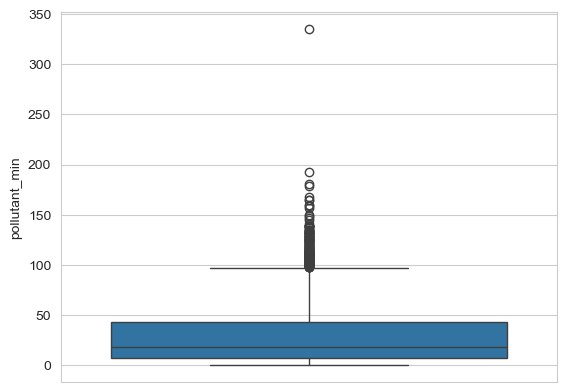

In [54]:
### Check outliers in each columns pollutant_cols = ['pollutant_min','pollutant_avg','pollutant_max']
sns.boxplot(air_quality_index['pollutant_min'])


In [55]:
# to find upper and lower limit q1 & q3 and IQR

# calculate lower limit
q1_pollutant_min= air_quality_index['pollutant_min'].quantile(0.25)
# to calculate upper limit
q3_pollutant_min= air_quality_index['pollutant_min'].quantile(0.75)

print('q1_pollutant_min:', q1_pollutant_min)
print('q3_pollutant_min:', q3_pollutant_min)

print('IQR Values for pollutant_min:', q3_pollutant_min - q1_pollutant_min)

q1_pollutant_min: 7.0
q3_pollutant_min: 43.0
IQR Values for pollutant_min: 36.0


In [56]:
lower_fence_pollutant_min= q1_pollutant_min - 1.5 * (q3_pollutant_min - q1_pollutant_min)
print('lower_fence of pollutant_min:', lower_fence_pollutant_min)

lower_fence of pollutant_min: -47.0


In [57]:
upper_fence_pollutant_min=q3_pollutant_min + 1.5 * (q3_pollutant_min - q1_pollutant_min)
print('upper_fence:', upper_fence_pollutant_min)

upper_fence: 97.0


In [58]:
air_quality_index[air_quality_index['pollutant_min']> upper_fence_pollutant_min]

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg,aqi_sub_index,calculated_aqi,aqi_category,dominant_pollutant,pollutants_with_valid_data,official_aqi_data_criteria_met
66,India,Bihar,Munger,"Town Hall, Munger - BSPCB",23-10-2026 16:00:00,25.376776,86.471523,OZONE,335.0,335.0,335.0,324.1,473.0,Severe,CO,4,False
114,India,Delhi,Delhi,"Dwarka-Sector 8, Delhi - DPCC",23-10-2026 16:00:00,28.571027,77.071901,PM2.5,110.0,353.0,280.0,412.5,412.5,Severe,PM2.5,7,True
115,India,Delhi,Delhi,"Dwarka-Sector 8, Delhi - DPCC",23-10-2026 16:00:00,28.571027,77.071901,PM10,133.0,451.0,258.0,208.0,412.5,Severe,PM2.5,7,True
122,India,Delhi,Delhi,"Mundka, Delhi - DPCC",23-10-2026 16:00:00,28.684678,77.076574,PM10,135.0,483.0,268.0,218.0,415.9,Severe,CO,7,True
125,India,Delhi,Delhi,"Wazirpur, Delhi - DPCC",23-10-2026 16:00:00,28.699793,77.165453,PM10,135.0,428.0,217.0,178.1,500.0,Severe,CO,7,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3590,India,Uttar Pradesh,Ghaziabad,"Wave City, Ghaziabad - UPPCB",23-10-2026 16:00:00,28.646675,77.489049,CO,104.0,117.0,109.0,500.0,500.0,Severe,CO,6,True
3598,India,Rajasthan,Jodhpur,"Samrat Ashok Udhyan, Jodhpur - RSPCB",23-10-2026 16:00:00,26.253384,72.976571,PM10,101.0,411.0,192.0,161.5,318.0,Very Poor,CO,7,True
3620,India,Uttar Pradesh,Mathura,"Pali Dungra, Mathura - UPPCB",23-10-2026 16:00:00,27.410954,77.550619,PM10,115.0,175.0,144.0,129.6,418.9,Severe,CO,7,True
3625,India,Uttar Pradesh,Meerut,"MIET College, Meerut - UPPCB",23-10-2026 16:00:00,28.972677,77.641018,PM10,104.0,202.0,170.0,146.8,430.9,Severe,CO,7,True


In [59]:
new_air_quality_index=air_quality_index[air_quality_index['pollutant_min']< upper_fence_pollutant_min]

In [60]:
air_quality_index.shape

(3689, 17)

In [61]:
new_air_quality_index.shape

(3204, 17)

Display boxplot on new_air_quality_index data after removing outlairs of pollutant_min


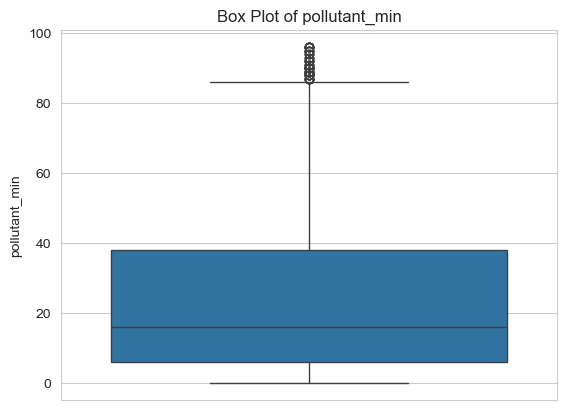

In [62]:
print('Display boxplot on new_air_quality_index data after removing outlairs of pollutant_min')


sns.boxplot(new_air_quality_index['pollutant_min'])

plt.title('Box Plot of pollutant_min')
plt.ylabel('pollutant_min')
plt.show()



In [63]:
air_quality_index['pollutant_min'] = air_quality_index['pollutant_min'].fillna(air_quality_index['pollutant_min'].median())

<Axes: ylabel='pollutant_max'>

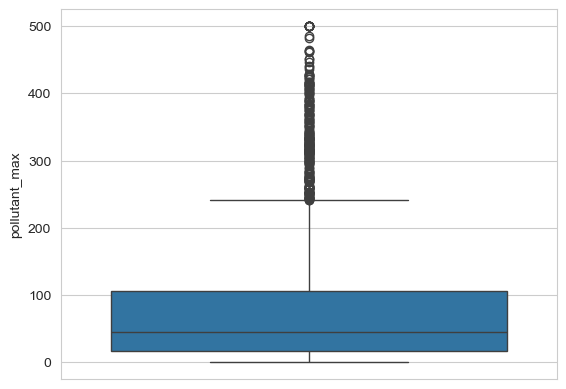

In [64]:
sns.boxplot(air_quality_index['pollutant_max'])

In [65]:
air_quality_index['pollutant_max'] = air_quality_index['pollutant_max'].fillna(air_quality_index['pollutant_max'].median())

<Axes: ylabel='pollutant_avg'>

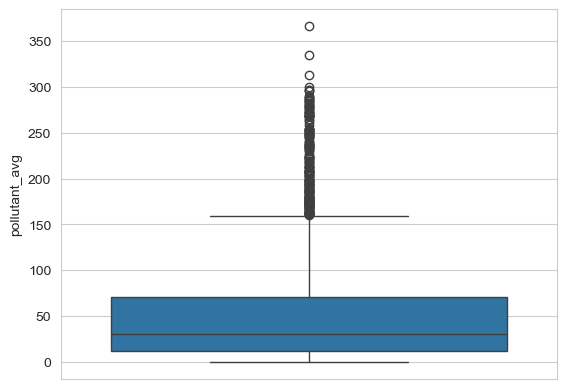

In [66]:
sns.boxplot(air_quality_index['pollutant_avg'])

In [67]:
air_quality_index['pollutant_avg'] = air_quality_index['pollutant_avg'].fillna(air_quality_index['pollutant_avg'].median())

In [68]:
### Handle Missing Values of Pollutant_min, Pollutant_avg, Pollutant_avg
print('Percentage of missing values in Pollutant')
pollutant_cols = ['pollutant_min','pollutant_avg','pollutant_max']

print(air_quality_index[pollutant_cols].isnull().sum())
print((air_quality_index[pollutant_cols].isnull().mean() * 100).round(2))

Percentage of missing values in Pollutant
pollutant_min    0
pollutant_avg    0
pollutant_max    0
dtype: int64
pollutant_min    0.0
pollutant_avg    0.0
pollutant_max    0.0
dtype: float64


In [69]:
air_quality_index['aqi_sub_index'] = air_quality_index['aqi_sub_index'].fillna(air_quality_index['aqi_sub_index'].median())

### 🔄 **Convert Data Types** – Convert columns to the appropriate data types.

In [70]:
### Checking data types of last_update columns
print(air_quality_index['last_update'].dtype)

object


In [71]:
## Convert Object[last_update] into datetime
air_quality_index['last_update'] = pd.to_datetime(air_quality_index['last_update'],errors='coerce', dayfirst=True)

In [72]:
air_quality_index['last_update'] = pd.to_datetime(air_quality_index['last_update'],format='%d-%m-%Y %H:%M:%S',errors='coerce')

In [73]:
air_quality_index['last_update']

0      2026-10-23 16:00:00
1      2026-10-23 16:00:00
2      2026-10-23 16:00:00
3      2026-10-23 16:00:00
4      2026-10-23 16:00:00
               ...        
3684   2026-10-23 16:00:00
3685   2026-10-23 16:00:00
3686   2026-10-23 16:00:00
3687   2026-10-23 16:00:00
3688   2026-10-23 16:00:00
Name: last_update, Length: 3689, dtype: datetime64[ns]

### 🗑️ Remove Irrelevant Data – Eliminate unnecessary or irrelevant information.

In [74]:
#air_quality_index = air_quality_index.drop(columns=['country'])
air_quality_index.columns = air_quality_index.columns.str.strip()

air_quality_index = air_quality_index.drop(columns=['country'],errors='ignore')
air_quality_index.head(2)

,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg,aqi_sub_index,calculated_aqi,aqi_category,dominant_pollutant,pollutants_with_valid_data,official_aqi_data_criteria_met
0,Bihar,Saharsa,"Police Line, Saharsa - BSPCB",2026-10-23 16:00:00,25.892357,86.590325,NH3,4.0,4.0,4.0,1.0,405.4,Severe,CO,7,True
1,Bihar,Saharsa,"Police Line, Saharsa - BSPCB",2026-10-23 16:00:00,25.892357,86.590325,OZONE,10.0,19.0,13.0,13.0,405.4,Severe,CO,7,True


## Data Validation check 

In [75]:
print('Data information:',air_quality_index.info())

print("no of null values:", air_quality_index.isnull().sum())

print('no of duplicate values:',air_quality_index.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3689 entries, 0 to 3688
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   state                           3689 non-null   object        
 1   city                            3689 non-null   object        
 2   station                         3689 non-null   object        
 3   last_update                     3689 non-null   datetime64[ns]
 4   latitude                        3689 non-null   float64       
 5   longitude                       3689 non-null   float64       
 6   pollutant_id                    3689 non-null   object        
 7   pollutant_min                   3689 non-null   float64       
 8   pollutant_max                   3689 non-null   float64       
 9   pollutant_avg                   3689 non-null   float64       
 10  aqi_sub_index                   3689 non-null   float64       
 11  calc

# Phase 3:📊🔍Exploratory Data Analysis (EDA) 💻📈

### AQI Caterory Distribution graph

In [76]:
air_quality_index.describe()
air_quality_index['calculated_aqi'].mean()
air_quality_index['aqi_category'].value_counts()


aqi_category
Severe          1596
Very Poor       1400
Poor             427
Moderate         203
Good              35
Satisfactory      28
Name: count, dtype: int64

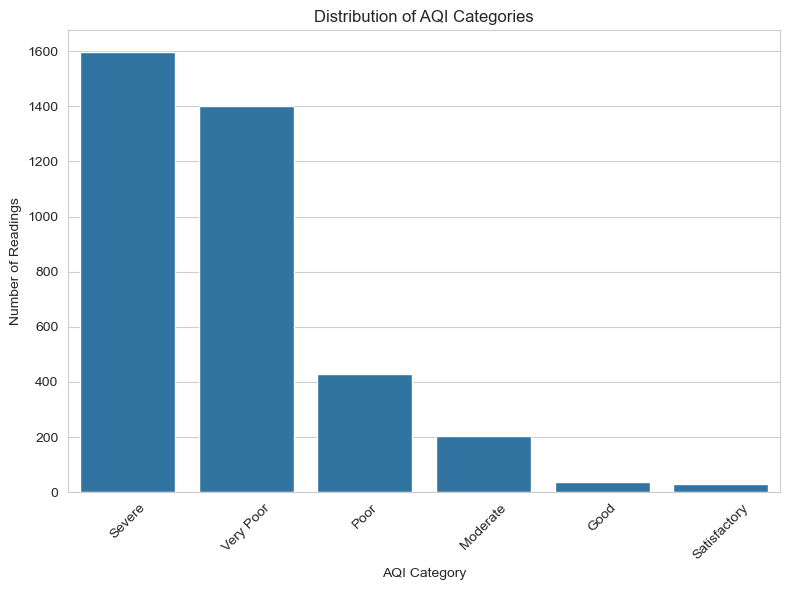

In [77]:

plt.figure(figsize=(8, 6))

sns.countplot(data=air_quality_index,x='aqi_category',order=air_quality_index['aqi_category'].value_counts().index)

plt.title('Distribution of AQI Categories')
plt.xlabel('AQI Category')
plt.ylabel('Number of Readings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

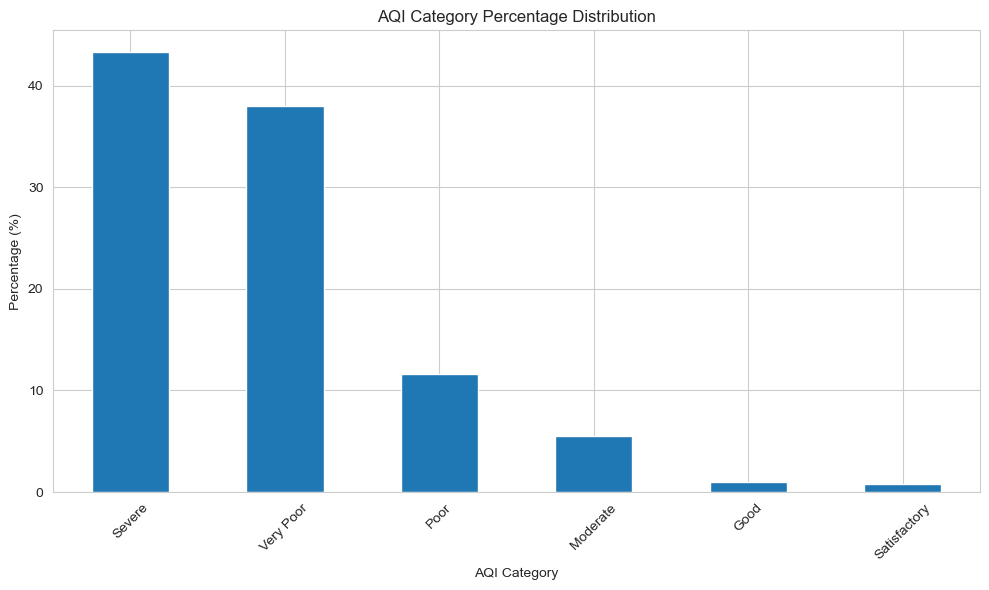

In [78]:
category_percent = (
    air_quality_index['aqi_category']
    .value_counts(normalize=True) * 100
)

category_percent.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('AQI Category Percentage Distribution')
plt.xlabel('AQI Category')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### State wise Distribution Graph

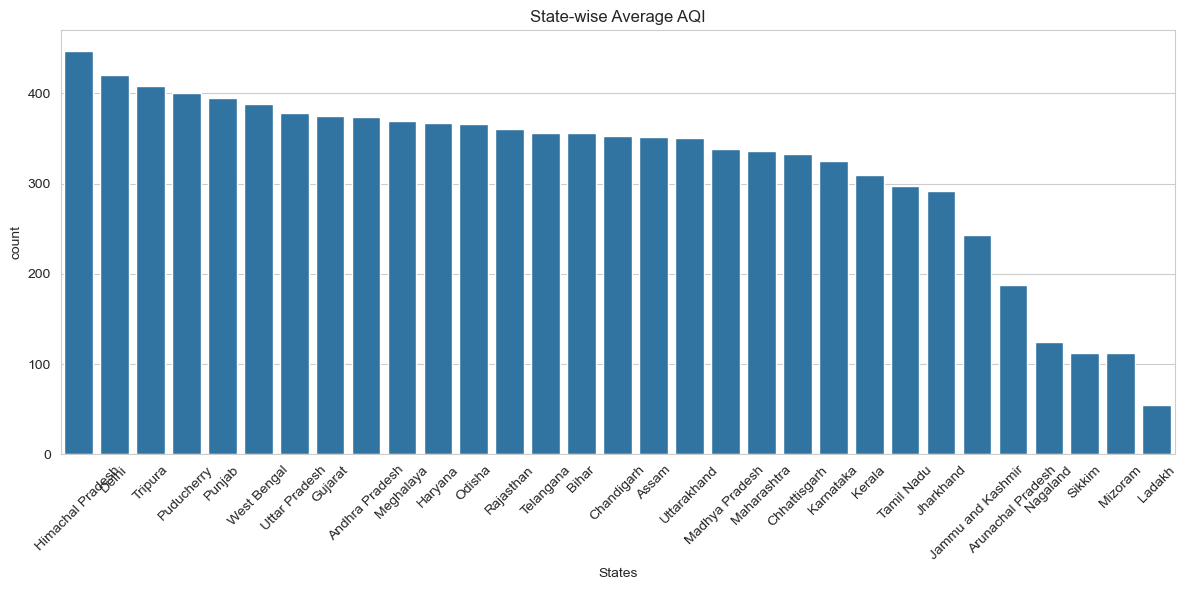

In [79]:
## City-wise Average AQI Bar Plot

# Har city ka average AQI
stae_aqi = air_quality_index.groupby('state')['calculated_aqi'].mean()

# Highest AQI wali cities pehle
stae_aqi = stae_aqi.sort_values(ascending=False)

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(x=stae_aqi.index, y=stae_aqi.values)

plt.title('State-wise Average AQI')
plt.xlabel('States')
plt.ylabel('count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Top 10 State wise Distribution plot

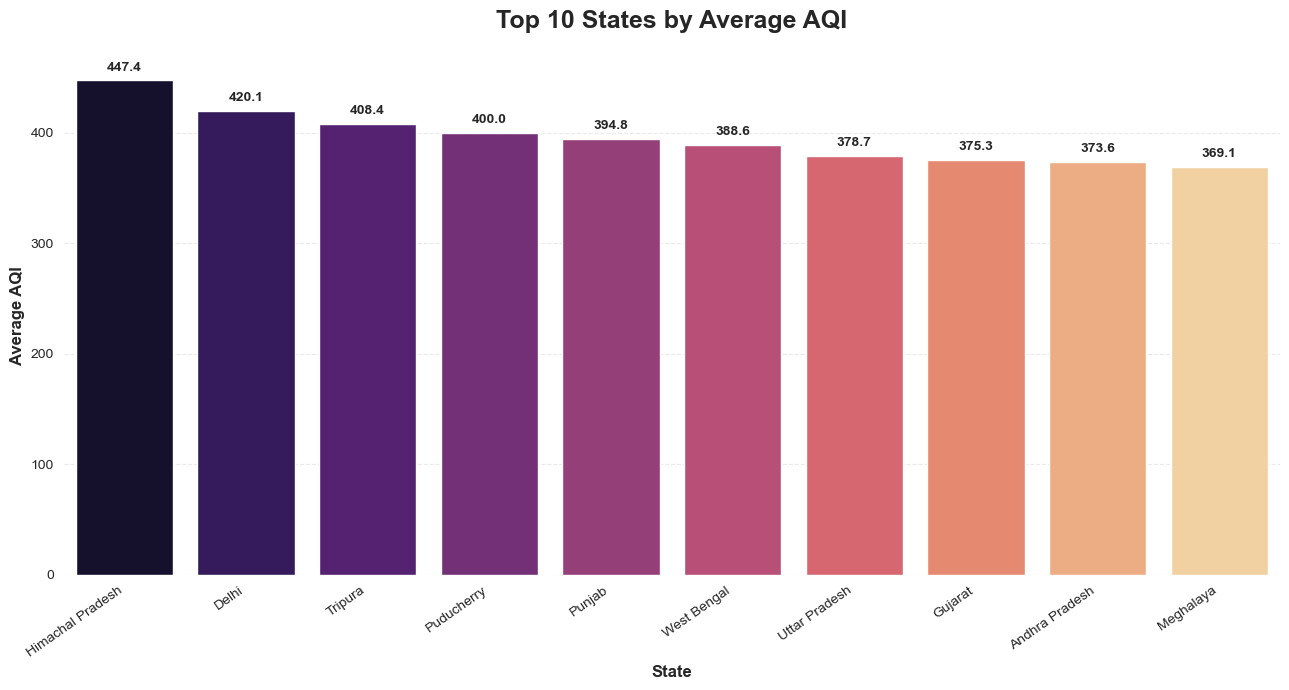

In [80]:

# Calculate average AQI for each state
state_aqi = (
    air_quality_index.groupby('state')['calculated_aqi']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Set chart style
sns.set_style("whitegrid")

# Create figure
plt.figure(figsize=(13, 7))

# Create bar plot
ax = sns.barplot(
    data=state_aqi,
    x='state',
    y='calculated_aqi',
    hue='state',
    palette='magma',
    legend=False
)

# Add values on top of bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f',
        padding=5,
        fontsize=10,
        fontweight='bold'
    )

# Customize chart
plt.title(
    'Top 10 States by Average AQI',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.xlabel('State', fontsize=12, fontweight='bold')
plt.ylabel('Average AQI', fontsize=12, fontweight='bold')

plt.xticks(rotation=35, ha='right', fontsize=10)

# Remove unnecessary borders
sns.despine(left=True, bottom=True)

# Grid customization
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.grid(axis='x', visible=False)

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

## Top 10 City-wise distribution plot

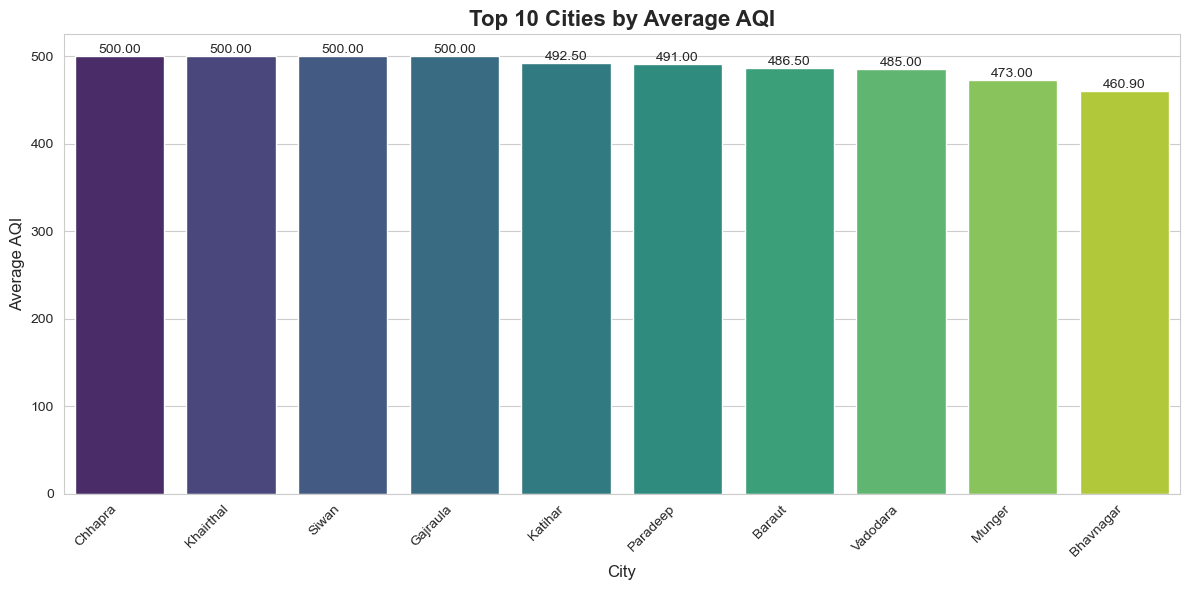

In [81]:
# Calculate average AQI for each city
city_aqi = air_quality_index.groupby('city')['calculated_aqi'].mean()

# Sort cities in descending order
city_aqi = city_aqi.sort_values(ascending=False)

# Select top 10 cities
top_10_cities = city_aqi.head(10)

# Plot bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_cities.index,
    y=top_10_cities.values,
    hue=top_10_cities.index,
    palette='viridis',
    legend=False
)

plt.title('Top 10 Cities by Average AQI', fontsize=16, fontweight='bold')
plt.xlabel('City', fontsize=12)
plt.ylabel('Average AQI', fontsize=12)

plt.xticks(rotation=45, ha='right')

# Display AQI values on bars
for i, value in enumerate(top_10_cities.values):
    plt.text(i, value, f'{value:.2f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

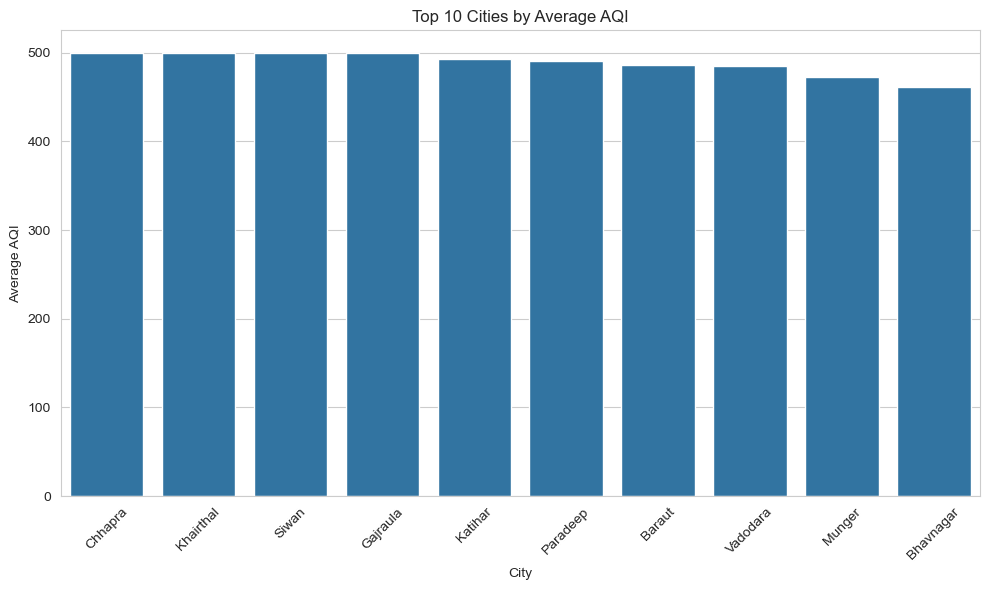

In [82]:
top_10_cities = city_aqi.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_10_cities.index, y=top_10_cities.values)

plt.title('Top 10 Cities by Average AQI')
plt.xlabel('City')
plt.ylabel('Average AQI')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Pollutant -wise plot

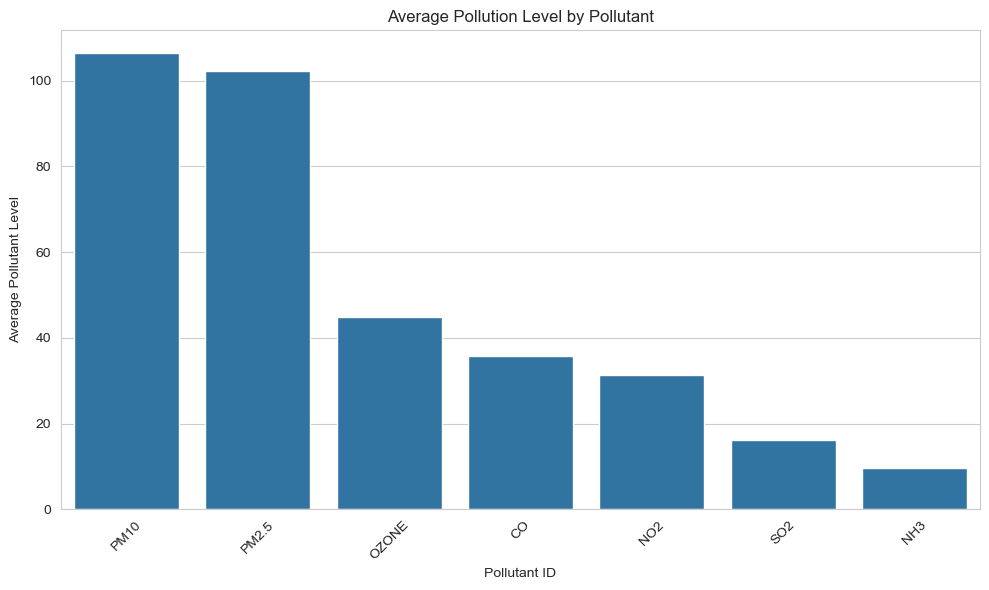

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Pollutant average ko numeric banana
air_quality_index['pollutant_avg'] = pd.to_numeric(
    air_quality_index['pollutant_avg'],
    errors='coerce'
)

# Har pollutant ka average level
pollutant_avg = air_quality_index.groupby(
    'pollutant_id'
)['pollutant_avg'].mean().sort_values(ascending=False)

# Graph
plt.figure(figsize=(10, 6))
sns.barplot(x=pollutant_avg.index, y=pollutant_avg.values)

plt.title('Average Pollution Level by Pollutant')
plt.xlabel('Pollutant ID')
plt.ylabel('Average Pollutant Level')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

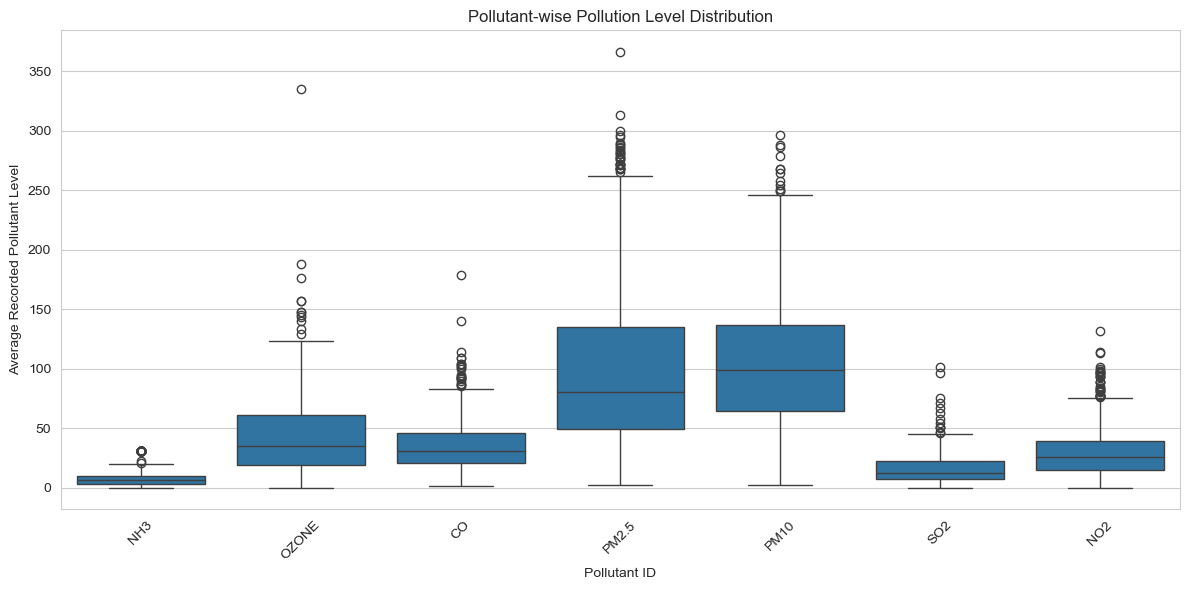

In [84]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=air_quality_index,
    x='pollutant_id',
    y='pollutant_avg'
)

plt.title('Pollutant-wise Pollution Level Distribution')
plt.xlabel('Pollutant ID')
plt.ylabel('Average Recorded Pollutant Level')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

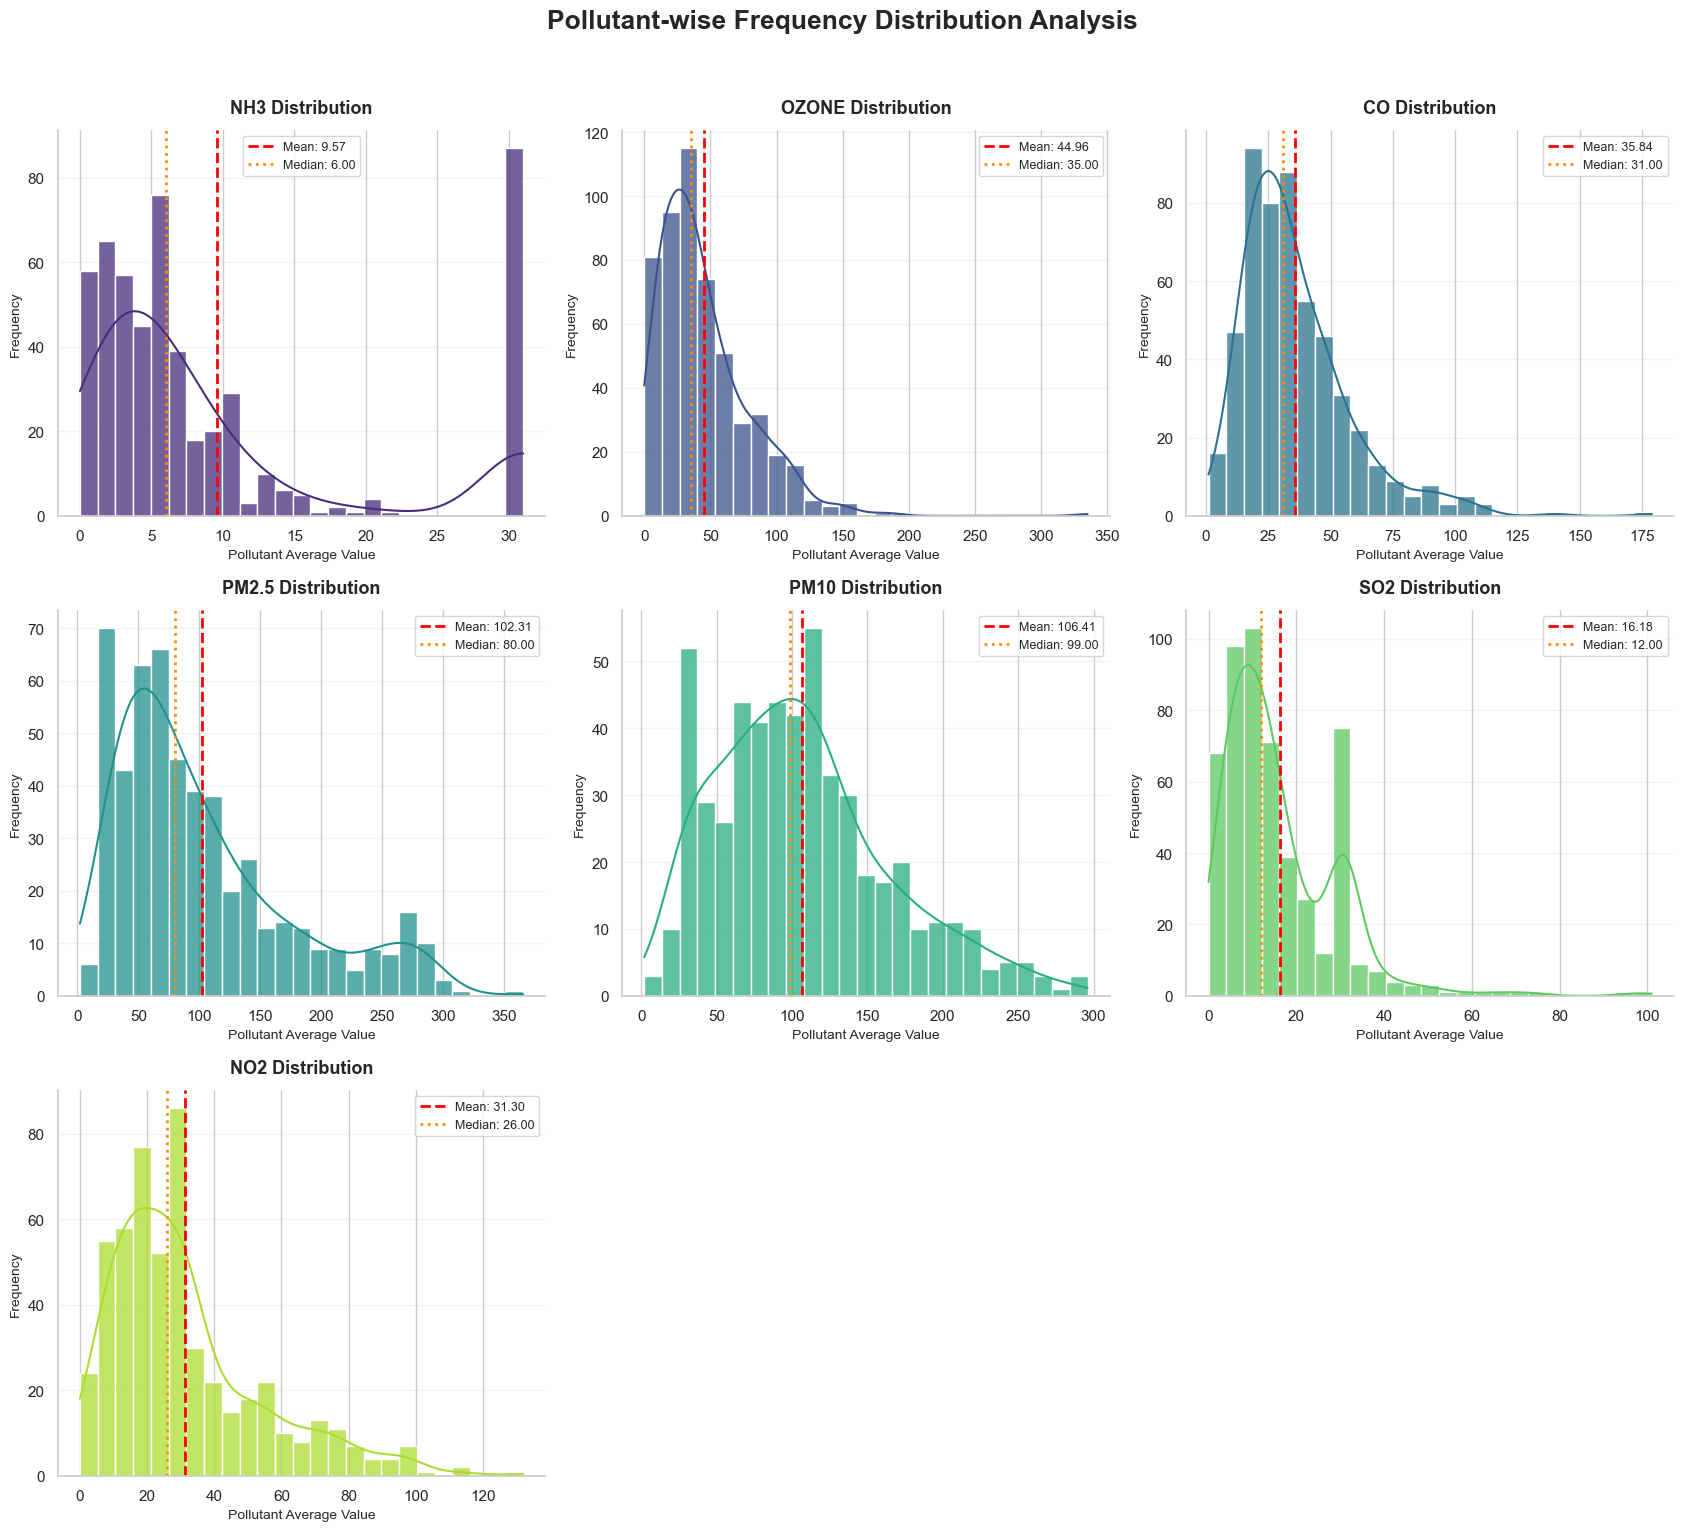

In [91]:


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Professional chart style
sns.set_theme(style="whitegrid", context="notebook")

# Convert pollutant_avg into numeric
air_quality_index['pollutant_avg'] = pd.to_numeric(
    air_quality_index['pollutant_avg'],
    errors='coerce'
)

# Get unique pollutants
pollutants = air_quality_index['pollutant_id'].dropna().unique()

# Layout settings
cols = 3
rows = math.ceil(len(pollutants) / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(17, 5 * rows)
)

# Handle single subplot case
axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

# Color palette
colors = sns.color_palette("viridis", len(pollutants))

for i, pollutant in enumerate(pollutants):

    ax = axes[i]

    data = air_quality_index.loc[
        air_quality_index['pollutant_id'] == pollutant,
        'pollutant_avg'
    ].dropna()

    if data.empty:
        ax.set_visible(False)
        continue

    # Histogram with KDE
    sns.histplot(
        data,
        bins=25,
        kde=True,
        color=colors[i],
        edgecolor='white',
        alpha=0.75,
        linewidth=1,
        ax=ax
    )

    # Mean and median lines
    mean_value = data.mean()
    median_value = data.median()

    ax.axvline(
        mean_value,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f'Mean: {mean_value:.2f}'
    )

    ax.axvline(
        median_value,
        color='darkorange',
        linestyle=':',
        linewidth=2,
        label=f'Median: {median_value:.2f}'
    )

    # Titles and labels
    ax.set_title(
        f'{pollutant} Distribution',
        fontsize=13,
        fontweight='bold',
        pad=12
    )

    ax.set_xlabel('Pollutant Average Value', fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)

    ax.legend(fontsize=9, frameon=True)
    ax.grid(axis='y', alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hide extra plots
for j in range(len(pollutants), len(axes)):
    axes[j].set_visible(False)

# Main title
fig.suptitle(
    'Pollutant-wise Frequency Distribution Analysis',
    fontsize=19,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()


## Correlation Analysis